# MCP `invierte-obras`: proceso e informe

Servidor MCP con datos en vivo de **inversiones públicas (Invierte.pe, MEF)** y **obras públicas (INFOBRAS,
Contraloría)** del Perú, construido y evaluado para el proyecto de la Sesión 04 del curso (*MCP en Claude Code*).

Este notebook reúne todo el trabajo: el proceso de construcción, el servidor funcionando, las pruebas, la evaluación
(memoria contra web contra MCP), la verificación a mano en la web, los prompts y las herramientas usadas.

**Repositorio:** <https://github.com/IvettexMamani/Proyecto_Obras>
**Fecha de la evaluación:** 28 de octubre de 2026

| Resultado | |
|---|---|
| Pruebas | **8 de 8** en verde |
| Evaluación, 10 preguntas con Claude Haiku | Memoria **0/10**, web **0/10**, MCP **10/10** |
| Cifras comprobadas a mano en la web | 4: tres coinciden y una difiere en 1 (mapa contra API de INFOBRAS) |

**Contenido**

1. Punto de partida: la tarea y la rúbrica
2. Fuentes de datos
3. El servidor en vivo
4. El proceso, parte por parte
5. Pruebas
6. Evaluación
7. Verificación a mano en la web
8. Ejemplo de uso: informe de Tacna con el prompt
9. Problemas y soluciones
10. Prompts
11. Herramientas usadas
12. Conclusión y aprendizajes

## 1. Punto de partida: la tarea y la rúbrica

La tarea pide construir un servidor MCP en 100 minutos, en seis partes:

| Parte | Tiempo | Qué se pide |
|---|---|---|
| 0 · Preparar | 10 min | Copiar la carpeta, correr las pruebas, conectar el MCP de documentación |
| 1 · Servidor | 35 min | Completar el servidor hasta tener 8 de 8 pruebas en verde |
| 2 · Conectar | 10 min | `.mcp.json` con el servidor propio y `fetch`; probar una herramienta, un `@` y un `/` |
| 3 · Evaluar | 25 min | Preguntas propias en `preguntas.csv` y `uv run evaluar.py`: memoria contra MCP |
| 4 · Informe | 15 min | Informe con una figura y dos cifras verificadas a mano; push a GitHub |
| 5 · Margen | 5 min | Para lo que falle |

La plantilla del curso era un MCP del BCRP, pero el proyecto se hizo sobre un MCP propio de inversiones y obras
públicas, con las mismas seis partes y la misma rúbrica de 20 puntos:

| Criterio | Puntos | Qué se mira | Estado |
|---|---|---|---|
| Pruebas | 6 | 8 de 8 en verde | ✅ 8 de 8 |
| Herramienta propia | 3 | Útil, con un docstring que diga cuándo usarla y con su fuente en la respuesta | ✅ `resumen_obras_departamento` |
| Recurso y prompt | 2 | Funcionan en Claude Code con `@` y con `/` | ✅ El `/` se probó en Claude Code; el `@` funciona en las pruebas y por stdio |
| `.mcp.json` | 2 | En el repo, con el servidor propio y `fetch`, y sin claves | ✅ `invierte-obras` + `fetch` |
| Evaluación | 4 | 10 preguntas, dos propias con la verdad revisada a mano; un experimento extra | ✅ 10 preguntas, 2 revisadas a mano, experimento web |
| Informe | 3 | Qué acertó y qué no, por qué, una figura y dos cifras comprobadas en la web | ✅ Secciones 6 y 7 |

La primera versión de `server.py`, con cuatro herramientas, se escribió en una conversación anterior con Claude. Esta
etapa la completó, la probó y la evaluó.

## 2. Fuentes de datos

El servidor consulta en vivo tres servicios públicos, sin claves ni CAPTCHA:

| Fuente | Qué aporta | Endpoints que usa el servidor |
|---|---|---|
| **INFOBRAS** (Contraloría) | Obras públicas y su estado: paralizada, en ejecución, finalizada | `Mapa/busqueda/obras/groupby/departamento`, `Mapa/busqueda/obras`, `Mapa/ListaParametrosComentario` |
| **Invierte.pe, Banco de Inversiones** (MEF) | Búsqueda de inversiones, costos y ejecución del año | `ConsultaPublica/traeListaProyectoConsultaAvanzada`, `general/traeListaDepartamento` |
| **Invierte.pe, ficha SSI** (MEF) | Ficha de seguimiento de un CUI, devengados y registro de obras paralizadas de la Ley 31589 | `Ssi/traeDetInvSSI`, `Dashboard/traeDevengSSI`, `paraliza/traeListaParalizaPublico` |

```
 Usuario en Claude Code ──(pregunta, @ o /)──▶ Claude
                                                 │ stdio
                         ┌───────────────────────┴───────────────────────┐
                         ▼                                               ▼
              server.py (invierte-obras)                         mcp-server-fetch
                         │ HTTPS + cookies de sesión
         ┌───────────────┼─────────────────────────┐
         ▼               ▼                         ▼
     INFOBRAS     Banco de Inversiones        Ficha SSI
   (Contraloría)        (MEF)                   (MEF)
```

## 3. El servidor en vivo

`server.py` usa el SDK oficial de MCP para Python (`mcp` 2.3, clase `MCPServer`), `httpx` asíncrono y `truststore`.
Las celdas siguientes lo importan y lo llaman **en memoria**, con el mismo cliente que usan las pruebas, igual que lo
haría Claude Code. Los datos son en vivo: si se ejecuta otro día, las cifras pueden cambiar. Cada respuesta trae
`fuente` y `consultado`.

> Requisitos: `uv sync` y el kernel del `.venv` del proyecto. En una red con inspección de HTTPS, el servidor ya usa
> los certificados del sistema con `truststore`.

In [1]:
import json
import logging
import subprocess
import sys

import pandas as pd
from IPython.display import Image, Markdown, display
from mcp import Client

from server import mcp

logging.getLogger("mcp").setLevel(logging.WARNING)
pd.set_option("display.max_colwidth", 110)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")


async def llamar(herramienta, **args):
    """Llama a una herramienta del MCP en memoria y devuelve su respuesta estructurada."""
    async with Client(mcp) as c:
        r = await c.call_tool(herramienta, args)
    if r.is_error:
        raise RuntimeError(r.content[0].text)
    return r.structured_content

### 3.1 Qué ofrece: herramientas, recursos y prompt

| Tipo | Nombre | Para qué |
|---|---|---|
| Herramienta | `contar_obras_por_departamento` | Conteo de obras de INFOBRAS por departamento |
| Herramienta | `listar_obras_infobras` | Lista paginada de obras, con su CUI |
| **Herramienta propia** | `resumen_obras_departamento` | Recorre **todas** las páginas y devuelve totales, promedio, la obra de mayor monto y el reparto por provincia, entidad, modalidad y año. Las cuentas las hace Python, no el modelo |
| Herramienta | `buscar_inversiones` | Búsqueda en el Banco de Inversiones |
| Herramienta | `detalle_inversion` | Ficha SSI: costos (a) y total (a+b+c+d), devengados y Ley 31589 |
| Recurso (`@`) | `invierte://inversion/{cui}` | La ficha de una inversión como JSON |
| Recurso (`@`) | `infobras://paralizadas/por-departamento` | Conteo de obras paralizadas por departamento |
| Prompt (`/`) | `informe_obras(departamento)` | Informe de obras paralizadas que cruza INFOBRAS con Invierte.pe |

El inventario que anuncia el servidor:

In [2]:
async with Client(mcp) as c:
    herramientas = (await c.list_tools()).tools
    plantillas = (await c.list_resource_templates()).resource_templates
    recursos = (await c.list_resources()).resources
    prompts = (await c.list_prompts()).prompts

pd.DataFrame(
    [("herramienta", t.name, (t.description or "").strip().splitlines()[0]) for t in herramientas]
    + [("recurso (plantilla)", p.uri_template, p.description) for p in plantillas]
    + [("recurso", str(r.uri), r.description) for r in recursos]
    + [("prompt", p.name, p.description) for p in prompts],
    columns=["tipo", "nombre", "descripción"],
)

,tipo,nombre,descripción
0,herramienta,contar_obras_por_departamento,Cuenta las obras públicas de INFOBRAS (Contraloría) en cada departamento según su estado.
1,herramienta,listar_obras_infobras,Lista las obras públicas de INFOBRAS de un departamento según su estado.
2,herramienta,resumen_obras_departamento,"Resume TODAS las obras de INFOBRAS de un departamento según su estado, con las cuentas hechas en Python."
3,herramienta,buscar_inversiones,Busca inversiones públicas en el Banco de Inversiones de Invierte.pe (MEF).
4,herramienta,detalle_inversion,Ficha de seguimiento de una inversión (SSI de Invierte.pe) a partir de su CUI.
5,recurso (plantilla),invierte://inversion/{cui},Ficha de seguimiento (SSI de Invierte.pe) de una inversión a partir de su CUI.
6,recurso,infobras://paralizadas/por-departamento,"Conteo de obras paralizadas en INFOBRAS por departamento, consultado al momento."
7,prompt,informe_obras,"Informe de las obras paralizadas de un departamento, con cada cifra sacada de INFOBRAS e Invierte.pe."


### 3.2 Obras paralizadas por departamento (`contar_obras_por_departamento`)

In [3]:
conteo = await llamar("contar_obras_por_departamento", estado="paralizada")
print(f"{conteo['fuente']} · consultado {conteo['consultado']} · total nacional: {conteo['total']:,}")
ranking = pd.Series(conteo["por_departamento"], name="obras paralizadas").to_frame()
ranking.insert(0, "puesto", ranking["obras paralizadas"].rank(ascending=False, method="min").astype(int))
ranking.head(12)

INFOBRAS - Contraloría General de la República · consultado 2026-10-28T21:24-05:00 · total nacional: 1,217


,puesto,obras paralizadas
CUSCO,1,227
PUNO,2,171
AYACUCHO,3,131
CAJAMARCA,4,80
APURIMAC,5,69
LIMA,6,61
HUANUCO,7,56
HUANCAVELICA,8,46
PIURA,9,42
AREQUIPA,10,38


### 3.3 La herramienta propia: `resumen_obras_departamento("Tacna")`

Recorre todas las páginas de INFOBRAS y hace las cuentas en Python. Así Claude cita una suma en vez de calcularla en
el texto.

In [4]:
tacna = await llamar("resumen_obras_departamento", departamento="Tacna", estado="paralizada")
print(f"{tacna['fuente']} · consultado {tacna['consultado']}")
print(f"Obras paralizadas: {tacna['total_obras']} · monto total: S/ {tacna['monto_total_soles']:,.2f} "
      f"· promedio: S/ {tacna['monto_promedio_soles']:,.2f}")
print("Obra de mayor monto:", tacna["obra_de_mayor_monto"]["nombre"][:90], "...",
      f"S/ {tacna['obra_de_mayor_monto']['monto_obra_soles']:,.2f}")
display(pd.DataFrame(tacna["por_provincia"]).T.astype({"obras": int}).rename_axis("provincia"))
display(pd.DataFrame(tacna["entidades_con_mas_obras"]).T.astype({"obras": int}).rename_axis("entidad").head(5))

INFOBRAS - Contraloría General de la República · consultado 2026-10-28T21:24-05:00
Obras paralizadas: 37 · monto total: S/ 499,646,766.07 · promedio: S/ 13,503,966.65
Obra de mayor monto: COMPONENTE 01 - 02 Y 04: MEJORAMIENTO DE LOS SERVICIOS DE SALUD DEL HOSPITAL HIPOLITO UNAN ... S/ 284,322,500.00


,obras,monto_soles
provincia,,
TARATA,18,"19,929,562.63"
JORGE BASADRE,11,"119,397,119.32"
TACNA,7,"360,046,828.06"
CANDARAVE,1,"273,256.06"


,obras,monto_soles
entidad,,
MUNICIPALIDAD DISTRITAL DE HEROES ALBARRACIN,14,"8,149,818.71"
MUNICIPALIDAD DISTRITAL DE ITE,7,"106,868,716.12"
MUNICIPALIDAD PROVINCIAL DE JORGE BASADRE,3,"6,293,515.20"
GOBIERNO REGIONAL TACNA,2,"285,174,551.09"
MUNICIPALIDAD DISTRITAL DE CIUDAD NUEVA,2,"34,833,364.77"


### 3.4 Ficha de una inversión (`detalle_inversion("2192844")`, Hospital Hipólito Unanue)

La ficha tiene dos costos que se confunden con facilidad. El **costo actualizado (a)** es S/ 632,167,753.73, y el
**costo total (a+b+c+d)** es S/ 633,486,449.64. La diferencia son las controversias (c). La herramienta devuelve los
dos.

In [5]:
ficha = await llamar("detalle_inversion", cui="2192844")
campos = ["nombre", "entidad", "estado", "beneficiarios", "costo_actualizado", "costo_control_concurrente",
          "costo_controversias", "monto_carta_fianza", "costo_total_actualizado", "devengado_acumulado",
          "avance_financiero_pct", "primer_devengado", "ultimo_devengado", "ficha_url"]
print(f"{ficha['fuente']} · consultado {ficha['consultado']}")
display(pd.Series({k: ficha.get(k) for k in campos}, name="valor").to_frame())
pd.DataFrame(ficha["registro_obras_paralizadas_ley_31589"])[["fec_paraliza", "des_motivo", "des_estado", "val_avance_fisico"]]

Invierte.pe - Seguimiento de Inversiones, SSI (MEF) · consultado 2026-10-28T21:24-05:00


,valor
nombre,"MEJORAMIENTO DE LOS SERVICIOS DE SALUD DEL HOSPITAL HIPOLITO UNANUE DE TACNA, DISTRITO DE TACNA, PROVINCIA..."
entidad,GOBIERNO REGIONAL TACNA
estado,ACTIVO
beneficiarios,324498
costo_actualizado,"632,167,753.73"
costo_control_concurrente,0
costo_controversias,"1,318,695.91"
monto_carta_fianza,0
costo_total_actualizado,"633,486,449.64"
devengado_acumulado,"289,106,891.76"


,fec_paraliza,des_motivo,des_estado,val_avance_fisico
0,2024-04-10,"RESOLUCION DE CONTRATO N° 053-2015, REALIZADA POR EL CONSORCIO SALUD TACNA MEDIANTE CARTA NOTARIAL N° 062 ...",31/12/2024 En actos previos para elaborar el expediente técnico de saldo de obra,40


### 3.5 El recurso (`@`) y el prompt (`/`)

En Claude Code se usan así:

- `@invierte-obras:invierte://inversion/2192844 ¿Cuántos beneficiarios declara esta inversión?`
- `/mcp__invierte-obras__informe_obras Tacna`

Aquí se leen directamente:

In [6]:
async with Client(mcp) as c:
    recurso = await c.read_resource("invierte://inversion/2192844")
    prompt = await c.get_prompt("informe_obras", {"departamento": "Tacna"})

print("Recurso invierte://inversion/2192844 → beneficiarios:", json.loads(recurso.contents[0].text)["beneficiarios"])
print("\nPrompt informe_obras(Tacna):\n")
print(prompt.messages[0].content.text)

Recurso invierte://inversion/2192844 → beneficiarios: 324498

Prompt informe_obras(Tacna):

Prepara un informe breve sobre las obras públicas paralizadas en Tacna.

1. Usa resumen_obras_departamento(departamento='Tacna') para el número de obras, el monto total y el reparto por provincia y entidad. No sumes a mano.
2. Usa contar_obras_por_departamento para ubicar al departamento en el ranking nacional.
3. Para las 3 obras de mayor monto que tengan CUI, llama a detalle_inversion y di si siguen paralizadas según Invierte.pe: estado, último mes con devengado y registro de la Ley 31589.
4. Cierra con las advertencias: el estado en INFOBRAS lo registra cada entidad y puede estar desactualizado, y estos conteos no son los de los informes trimestrales de la Contraloría.

Formato: un título, tres cifras clave, una tabla con las obras revisadas (CUI, entidad, monto, estado en Invierte.pe) y la fuente y fecha de consulta de cada cifra.


## 4. El proceso, parte por parte

### Parte 0 · Preparar
- Se agregó `pytest` (`uv add --dev pytest`) y se escribió **`test_server.py`**, el contrato del servidor: 8 pruebas que
  llaman al servidor en memoria con datos reales.
- Primera corrida: **3 de 8 en verde**. Fallaban las tres piezas por construir (herramienta propia, recurso y prompt),
  además de dos errores reales que las pruebas destaparon.

### Parte 1 · Servidor
- **Error 1:** el cliente HTTP fallaba con *"Event loop is closed"*. La clase `Sitio` ahora crea un cliente nuevo
  cuando cambia el *event loop*.
- **Error 2:** `detalle_inversion` devolvía el CUI como número y `buscar_inversiones` como texto. Ahora los dos lo
  devuelven como texto.
- Se extrajo `_pagina_obras()` para compartir la paginación.
- Se agregaron `resumen_obras_departamento`, los dos recursos y el prompt `informe_obras`.
- Resultado: **8 de 8 en verde**.

### Parte 2 · Conectar
- `.mcp.json` quedó con dos servidores y sin claves: `invierte-obras` (`uv run server.py`) y
  `fetch` (`mcp-server-fetch`, lanzado con `uvx` y `truststore`).
- Se lanzaron ambos servidores por stdio, como lo hace Claude Code, y se probaron una herramienta, un recurso y un
  prompt de cada uno.
- Con `claude -p` y Haiku se comprobó que **Claude elige la herramienta propia** para sumar montos.
- El `@` y el `/` no se pueden probar con `claude -p`, porque el modo no interactivo no los expande. Se probaron en la
  sesión interactiva: `/mcp__invierte-obras__informe_obras tacna` funcionó (sección 8).

### Parte 3 · Evaluar
- `preguntas.csv`: 10 preguntas con una cifra oficial y una tolerancia. Las verdades se sacaron con un script aparte
  que no usa `server.py`, y dos se revisaron después a mano en la web.
- `evaluar.py`, adaptado del proyecto del curso, le hace cada pregunta a Claude con `claude -p` en modo `memoria`,
  `web` o `mcp`.
- Se agregó `--recalificar` para volver a calificar cuando cambia una verdad, sin volver a llamar a Claude.

### Parte 4 · Informe y entrega
- La figura `grafico.png` (generada con `grafico.py`), el informe, este notebook y el push a GitHub, encima del commit
  inicial con la licencia MIT del repositorio.

## 5. Pruebas

| Prueba | Qué revisa |
|---|---|
| `test_contar_obras_paralizadas` | El total es la suma por departamento y trae la fuente |
| `test_listar_obras_de_un_departamento` | El listado de Tacna cuadra con el conteo |
| `test_buscar_inversiones` | La búsqueda «hospital» en Tacna encuentra el CUI 2341243 |
| `test_detalle_inversion` | La ficha del CUI 2341243: nombre, monto viable, fecha de viabilidad, costos |
| `test_errores_claros` | Un CUI inválido y un departamento inexistente dan errores que se entienden |
| `test_resumen_sin_cuentas_a_mano` | La herramienta propia suma igual que el listado completo |
| `test_un_recurso` | Existe `invierte://inversion/{cui}` y devuelve la ficha |
| `test_un_prompt` | Existe `informe_obras` y menciona el departamento y la herramienta propia |

In [7]:
corrida = subprocess.run([sys.executable, "-m", "pytest", "-q", "--color=no", "test_server.py"],
                         capture_output=True, text=True)
print(corrida.stdout.strip().splitlines()[-1])

8 passed in 11.65s


## 6. Evaluación: ¿inventa cifras Claude?

Cada pregunta se le hace a Claude Code en modo no interactivo (`claude -p`, Claude Haiku), con una instrucción que
pide responder un número o `null` si no lo sabe, y se califica contra la cifra oficial. Hay tres modos:

- **memoria**: sin herramientas.
- **web**: con WebSearch y WebFetch.
- **mcp**: solo con las herramientas de `invierte-obras`.

### 6.1 Las 10 preguntas

In [8]:
preguntas = pd.read_csv("preguntas.csv")
preguntas[["id", "pregunta", "verdad", "tolerancia"]]

,id,pregunta,verdad,tolerancia
0,paralizadas_peru,"Según INFOBRAS de la Contraloría, ¿cuántas obras públicas figuran con estado «Paralizada» en todo el Perú ...","1,217.00",10
1,paralizadas_cusco,"Según INFOBRAS de la Contraloría, ¿cuántas obras públicas figuran con estado «Paralizada» en el departamen...",227.00,3
2,paralizadas_tacna,"Según INFOBRAS de la Contraloría, ¿cuántas obras públicas figuran con estado «Paralizada» en el departamen...",36.00,1
3,ejecucion_tacna,"Según INFOBRAS de la Contraloría, ¿cuántas obras públicas figuran con estado «En Ejecución» en el departam...",483.00,5
4,monto_paralizadas_tacna,"Según INFOBRAS de la Contraloría, ¿cuánto suman, en soles, los montos de obra de todas las obras paralizad...","499,646,766.07",1000000
5,costo_essalud_tacna,"Según la ficha de seguimiento de Invierte.pe (MEF), ¿cuál es el costo actualizado, en soles, de la inversi...","445,775,154.32",1000
6,beneficiarios_essalud_tacna,"Según Invierte.pe (MEF), ¿cuántos beneficiarios declara la inversión con CUI 2341243 (Hospital III Daniel ...","306,839.00",1
7,devengado_unanue,"Según la ficha de seguimiento de Invierte.pe (MEF), ¿cuál es el devengado acumulado, en soles, de la inver...","289,106,891.76",1000
8,viable_puentes,"Según Invierte.pe (MEF), ¿cuál es el monto viable, en soles, de la inversión con CUI 2283964 (reemplazo de...","159,647,875.00",1000
9,anio_paralizacion_puentes,"Según el registro de obras paralizadas de la Ley 31589 en Invierte.pe, ¿en qué año se paralizó la obra de ...","2,020.00",0


### 6.2 Resultados

`resultados_base.csv` es la corrida base, solo memoria contra MCP. `resultados.csv` es el experimento extra, con los
tres modos.

In [9]:
def tabla(res):
    t = res.groupby("modo").resultado.value_counts().unstack(fill_value=0)
    t = t.reindex(columns=["acierta", "se equivoca", "no sabe"], fill_value=0)
    t["segundos promedio"] = res.groupby("modo").segundos.mean().round(1)
    return t.reindex([m for m in ("memoria", "web", "mcp") if m in t.index])


base = pd.read_csv("resultados_base.csv")
final = pd.read_csv("resultados.csv")
display(Markdown("**Corrida base: memoria contra MCP**"), tabla(base))
display(Markdown("**Experimento extra: memoria, web y MCP**"), tabla(final))

**Corrida base: memoria contra MCP**

resultado,acierta,se equivoca,no sabe,segundos promedio
modo,,,,
memoria,0,0,10,10.40
mcp,10,0,0,16.10


**Experimento extra: memoria, web y MCP**

resultado,acierta,se equivoca,no sabe,segundos promedio
modo,,,,
memoria,0,0,10,8.30
web,0,0,10,18.90
mcp,10,0,0,13.00


In [10]:
# resultado de cada pregunta en cada modo
final.pivot(index="id", columns="modo", values="resultado")[["memoria", "web", "mcp"]]

modo,memoria,web,mcp
id,,,
anio_paralizacion_puentes,no sabe,no sabe,acierta
beneficiarios_essalud_tacna,no sabe,no sabe,acierta
costo_essalud_tacna,no sabe,no sabe,acierta
devengado_unanue,no sabe,no sabe,acierta
ejecucion_tacna,no sabe,no sabe,acierta
monto_paralizadas_tacna,no sabe,no sabe,acierta
paralizadas_cusco,no sabe,no sabe,acierta
paralizadas_peru,no sabe,no sabe,acierta
paralizadas_tacna,no sabe,no sabe,acierta


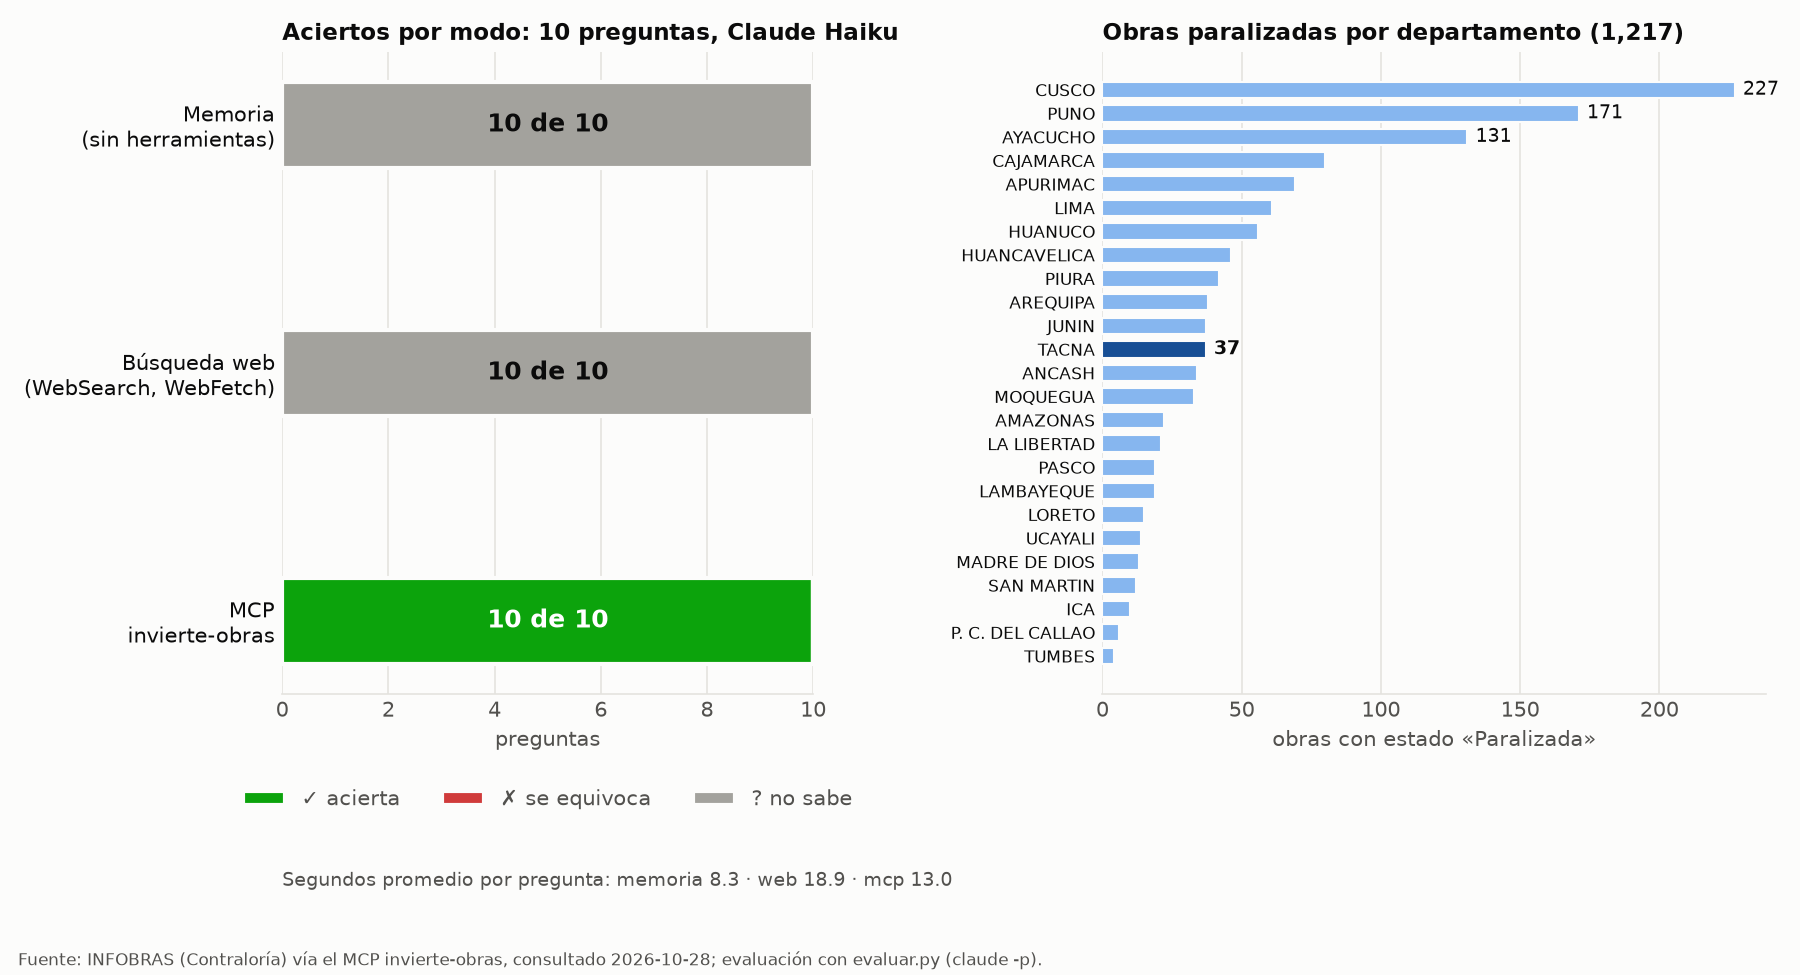

In [11]:
display(Image("grafico.png"))

### 6.3 Qué falló cada modo y por qué

La columna `fuente` de `resultados.csv` dice de dónde sacó Claude cada cifra, o por qué no pudo darla.

In [12]:
pd.set_option("display.max_colwidth", 300)
display(final[final.id == "paralizadas_tacna"][["modo", "valor", "verdad", "resultado", "fuente"]])
pd.set_option("display.max_colwidth", 110)

,modo,valor,verdad,resultado,fuente
6,memoria,NaN,36.00,no sabe,"No tengo acceso a internet ni a la consulta pública de INFOBRAS (Contraloría General de la República del Perú), y en este entorno no hay datos locales del portal. No puedo confirmar el número de obras con estado «Paralizada» en Tacna al 28 de octubre de 2026. Para obtenerlo, consulta directament..."
7,web,NaN,36.00,no sabe,"No pude consultar el portal INFOBRAS (infobras.contraloria.gob.pe): la página devuelta por WebFetch estaba vacía y no mostró listado de obras, estados ni fecha de corte. La búsqueda web solo dio cifras de otras fechas: 49 obras paralizadas en Tacna en un cuadro de la Contraloría de noviembre de ..."
8,mcp,37.00,36.00,acierta,"INFOBRAS - Contraloría General de la República, consulta del 28/10/2026 (20:51 -05:00) mediante contar_obras_por_departamento y resumen_obras_departamento (Tacna, estado ""Paralizada""). Ambas consultas coinciden en 37 obras."


- **Memoria, 10 «no sé».** Las preguntas piden datos vivos o cifras de un CUI concreto. Haiku reconoció que no tenía
  acceso a INFOBRAS ni a Invierte.pe y **no inventó ninguna cifra**: la instrucción «si no puedes saberlo con certeza,
  pon null» funcionó.
- **Web, 10 «no sé».** Es el resultado más interesante. Los portales de INFOBRAS y de la ficha SSI cargan los datos
  con JavaScript, así que WebFetch recibe una página vacía. Claude además probó URL de Invierte.pe que no existen
  (HTTP 404), y la búsqueda solo trajo cifras de prensa de otras fechas y con otra metodología: 2,572 obras paralizadas
  según un diario, o 49 en Tacna en un cuadro de 2022. Haiku las descartó porque no tenían la fecha de corte. Con las
  series del BCRP la web acertaba 7 de 8, porque esas cifras están publicadas en páginas estáticas. Aquí no.
- **MCP, 10 aciertos.** Cada respuesta usó una o dos llamadas: `contar_obras_por_departamento` o
  `resumen_obras_departamento` para INFOBRAS, y la ficha de `detalle_inversion` para los CUI. Es más lento que la
  memoria (13 s contra 8 s), pero es el único modo que responde.

Los conteos de INFOBRAS cambian a diario: las verdades valen para el 28/10/2026.

## 7. Verificación a mano en la web

Las dos preguntas propias, `paralizadas_tacna` y `devengado_unanue`, y otras dos cifras de la ficha SSI se revisaron a
mano en las páginas web oficiales:

| Cifra | Página | Web | MCP | Resultado |
|---|---|---|---|---|
| Obras paralizadas en Tacna | [Mapa de INFOBRAS](https://infobras.contraloria.gob.pe/InfobrasWeb/Mapa/Index) | **36** | 37 | Difiere en 1; dentro de la tolerancia |
| Devengado acumulado, CUI 2192844 | [Ficha SSI](https://ofi5.mef.gob.pe/ssi/Ssi/Index?codigo=2192844&tipo=2) | 289,106,891.76 | 289,106,891.76 | Coincide |
| Costo total actualizado (a+b+c+d), CUI 2192844 | Ficha SSI | 633,486,449.64 | 633,486,449.64 | Coincide |
| Beneficiarios, CUI 2192844 | Ficha SSI | 324,498 | 324,498 | Coincide |

**Tacna, 36 contra 37.** La API que usa el propio portal sigue devolviendo 37 obras, tanto en el conteo como en el
listado. El mapa muestra una menos, probablemente porque solo dibuja las obras con ubicación registrada (el listado no
trae coordenadas, así que no se puede confirmar). En `preguntas.csv` quedó como verdad la cifra revisada a mano, 36.
La respuesta del MCP (37) cabe en la tolerancia de 1, y los dos CSV se recalificaron con
`uv run evaluar.py --recalificar`.

**Dos costos en la misma ficha.** Al principio `detalle_inversion` solo devolvía el costo (a), mientras que el Banco de
Inversiones daba el total con el nombre «costo actualizado». Así, un modelo podía citar dos cifras distintas para el
mismo CUI. Ahora la herramienta devuelve los cuatro componentes y el `costo_total_actualizado`.

In [13]:
# las mismas cifras, consultadas ahora con el MCP
lista_tacna = await llamar("listar_obras_infobras", departamento="Tacna", estado="paralizada", por_pagina=100)
pd.DataFrame([
    ("obras paralizadas en Tacna", "36 (mapa web)", f"{lista_tacna['total']} (API de INFOBRAS)"),
    ("devengado acumulado, CUI 2192844", "289,106,891.76", f"{ficha['devengado_acumulado']:,.2f}"),
    ("costo total actualizado (a+b+c+d), CUI 2192844", "633,486,449.64", f"{ficha['costo_total_actualizado']:,.2f}"),
    ("beneficiarios, CUI 2192844", "324,498", f"{ficha['beneficiarios']:,}"),
], columns=["cifra", "web (revisada a mano)", "MCP (ahora)"])

,cifra,web (revisada a mano),MCP (ahora)
0,obras paralizadas en Tacna,36 (mapa web),37 (API de INFOBRAS)
1,"devengado acumulado, CUI 2192844","289,106,891.76","289,106,891.76"
2,"costo total actualizado (a+b+c+d), CUI 2192844","633,486,449.64","633,486,449.64"
3,"beneficiarios, CUI 2192844","324,498","324,498"


## 8. Ejemplo de uso: informe de Tacna con el prompt

En Claude Code, `/mcp__invierte-obras__informe_obras tacna` produjo un informe con las herramientas del MCP. Estas
son las tres obras de mayor monto, cruzadas con Invierte.pe (consulta del 28/10/2026, 21:14):

| CUI | Obra | Entidad | Monto (INFOBRAS) | Ley 31589 | Devengado 2026* | ¿Sigue paralizada? |
|---|---|---|---|---|---|---|
| 2192844 | Hospital Hipólito Unanue (componentes 1, 2 y 4) | Gobierno Regional Tacna | S/ 284,322,500.00 | Paralizada desde el 10/04/2024 por resolución de contrato; avance físico 40 % | S/ 3.44 M de un PIM de S/ 33.53 M | **Sí**; el gasto de 2026 va al expediente técnico de saldo |
| 2351041 | Riego presurizado, Ite | Municipalidad Distrital de Ite | S/ 57,001,668.22 | Paralizada desde el 05/07/2024 por arbitraje y medida cautelar; avance físico 20 % | S/ 95,583 de un PIM de S/ 444,515 | **Sí** |
| 2486784 | Movilidad urbana Av. Ecológica | Municipalidad Distrital de Coronel Gregorio Albarracín Lanchipa | S/ 31,593,108.67 | Sin registro | S/ 4.09 M de un PIM de S/ 4.11 M | **No confirmada**; el estado en INFOBRAS parece desactualizado |

\* Sacado del Banco de Inversiones (`buscar_inversiones`), porque la ficha SSI muestra 0 en el PIM y el devengado del
año (sección 9).

El informe también ubicó a Tacna en el puesto 12 de 25 departamentos, con 37 obras y S/ 499.6 millones, de los que el
57 % corresponde al Hospital Hipólito Unanue.

## 9. Problemas y soluciones

| Problema | Síntoma | Solución |
|---|---|---|
| El antivirus intercepta HTTPS | `UnknownIssuer` al instalar paquetes; `CERTIFICATE_VERIFY_FAILED` en Python | `UV_SYSTEM_CERTS=1` para `uv`; `truststore` en el servidor |
| `fetch` no podía leer páginas | «Failed to fetch robots.txt … connection issue» | Lanzarlo con `uvx --with truststore` y `truststore.inject_into_ssl()` |
| Cliente HTTP atado a un *event loop* cerrado | `RuntimeError: Event loop is closed` en las pruebas | `Sitio.client()` crea un cliente nuevo si cambió el loop |
| CUI con tipos distintos | `2341243 == '2341243'` fallaba | El CUI se devuelve siempre como texto |
| `@` y `/` no se expanden con `claude -p` | «No existe una herramienta llamada informe_obras» | Probarlos en la sesión interactiva de Claude Code |
| Verificación en el navegador | Las capturas de Claude in Chrome no respondían | La verificación la hizo la usuaria a mano |
| Mapa contra API de INFOBRAS | El mapa muestra 36 en Tacna; la API, 37 | Verdad = 36 (la revisada a mano), tolerancia 1, `--recalificar` |
| Dos costos en la misma ficha | S/ 633.49 M contra S/ 632.17 M (CUI 2192844) | `detalle_inversion` devuelve (a), (b), (c), (d) y el total |
| PIM y devengado del año en 0 en la ficha SSI | 0 en la SSI y valores reales en el Banco de Inversiones | **Pendiente**: tomar esas cifras del Banco de Inversiones |

## 10. Prompts

### 10.1 Lo que se le pidió a Claude Code en esta etapa

Texto de cada pedido, con algunas faltas de tipeo corregidas.

| # | Prompt | Qué hizo Claude |
|---|---|---|
| 1 | «Claude, retoma la conversación que estábamos teniendo para la creación de este MCP» | Revisó la carpeta, `server.py`, `.mcp.json` y la captura con las seis partes de la tarea |
| 2 | «Guíate de esos pasos para la ejecución de la tarea» | Encontró el proyecto de la Sesión 04 y empezó con la plantilla del BCRP |
| 3 | «Solo guíate de la imagen para los pasos a seguir» | Se detuvo y preguntó a qué MCP aplicar los pasos |
| 4 | Respuesta: «Mi MCP de Invierte» | Aplicó las seis partes a `invierte-obras` |
| 5 | «Que se cumpla lo que se solicita en la imagen» (con la rúbrica) | Agregó el experimento extra, la verificación en la web, el informe y la figura |
| 6 | «paralizadas_tacna me sale 36 en la página web que me brindaste, y 289,106,891.76 en devengado Unanue» | Confirmó que la API seguía en 37, cambió la verdad a 36 y agregó `--recalificar` |
| 7 | «Confirmar las dos cifras del informe: costo total de la inversión actualizado 633,486,449.64, y confirmo el número de beneficiarios» | Explicó (a) contra el total y amplió `detalle_inversion` |
| 8 | «¿Cómo lo pruebo?» | Dio los pasos para probar `@`, `/` y `fetch` en Claude Code |
| 9 | La URL del repositorio de GitHub | Revisó el remoto y subió los commits encima de la licencia |
| 10 | `/mcp__invierte-obras__informe_obras tacna` | Ejecutó el prompt del MCP y armó el informe de Tacna |
| 11 | «Crea un markdown para explicar todo el proceso…» | Escribió `PROCESO.md` |
| 12 | «Corrección: crea un ipynb con toda la info recolectada en proceso e informe.md» | Este notebook |

### 10.2 El prompt del servidor: `informe_obras`

Su texto completo se imprime en la celda de la sección 3.5. Le pide a Claude usar `resumen_obras_departamento` sin
sumar a mano, ubicar al departamento en el ranking, revisar en Invierte.pe las 3 obras de mayor monto y cerrar con
las advertencias sobre INFOBRAS.

### 10.3 Las instrucciones del servidor

> Datos en vivo de inversiones públicas (Invierte.pe, MEF) y obras públicas (INFOBRAS, Contraloría) del Perú. Indica
> siempre la fuente y la fecha de consulta. Para totales, montos y rankings de obras usa resumen_obras_departamento:
> no sumes a mano. El estado de una obra en INFOBRAS lo registra cada entidad y puede estar desactualizado (…)

### 10.4 El prompt de la evaluación (`evaluar.py`)

> Responde con un solo número en «valor», en la unidad que pide la pregunta. Si no puedes saberlo con certeza, pon
> valor null: no estimes. En «fuente» di de dónde sale la cifra.

### 10.5 Prompts para probar en Claude Code

| Prueba | Prompt | Esperado |
|---|---|---|
| Herramienta | «¿Cuánto suman, en soles, las obras paralizadas de Tacna según INFOBRAS?» | Llama a `resumen_obras_departamento` |
| Recurso | `@invierte-obras:invierte://inversion/2192844 ¿Cuántos beneficiarios declara esta inversión?` | 324,498 |
| Recurso | `@invierte-obras:infobras://paralizadas/por-departamento ¿Qué departamento tiene más obras paralizadas?` | Cusco |
| Prompt | `/mcp__invierte-obras__informe_obras Tacna` | Informe con tres cifras clave y tabla |
| Fetch | «Lee https://gofastmcp.com/llms.txt y dime qué secciones tiene la documentación de FastMCP.» | Lista de secciones |

## 11. Herramientas usadas

| Herramienta | Para qué |
|---|---|
| **Claude Code** (CLI) | Escribir y probar el código, conectar los MCP (`claude mcp add`), `/mcp`, `@` y `/` |
| **`claude -p`** | Evaluación automática, con `--strict-mcp-config`, `--mcp-config`, `--allowedTools` y `--json-schema` |
| **Claude Haiku** | Modelo de la evaluación: rápido y barato para 50 llamadas |
| **SDK de MCP para Python** (`mcp` 2.3) | `MCPServer` con `@mcp.tool`, `@mcp.resource` y `@mcp.prompt`; `Client` para las pruebas y este notebook |
| **uv / uvx** | Entorno, dependencias, `uv run` y lanzar `mcp-server-fetch` |
| **httpx** | Cliente HTTP asíncrono con cookies de sesión |
| **truststore** | Usar los certificados de Windows detrás del antivirus |
| **pytest** | El contrato de 8 pruebas |
| **pandas** | Preguntas, resultados y tablas |
| **matplotlib** | `grafico.png` |
| **mcp-server-fetch** | Segundo servidor del `.mcp.json`, para leer páginas web |
| **Claude in Chrome** | Intento de verificar cifras en las páginas web oficiales |
| **Skill `dataviz`** | Guía de colores, marcas y etiquetas para la figura |
| **Jupyter** (`nbformat`, `nbconvert`, `ipykernel`) | Este notebook |
| **git y GitHub** | Control de versiones y entrega |

**Archivos del repositorio:** `server.py`, `test_server.py`, `.mcp.json`, `preguntas.csv`, `evaluar.py`,
`resultados_base.csv`, `resultados.csv`, `grafico.py`, `grafico.png`, `informe.md`, `PROCESO.md`, `informe_mcp.ipynb`,
`README.md`, `pyproject.toml` y `uv.lock`. Los pasos para replicarlo están en `README.md`.

```bash
uv run pytest -q                              # 8 pruebas
uv run evaluar.py --modos memoria web mcp     # evaluación (unos minutos)
uv run grafico.py                             # figura
```

## 12. Conclusión y aprendizajes

**¿Cuándo vale la pena construir un MCP?** Cuando el dato vive detrás de un portal dinámico o de una API sin
documentar, como INFOBRAS o la ficha SSI, cuando cambia a diario o cuando la respuesta exige cuentas sobre muchas
páginas. En esos casos, ni la memoria ni la búsqueda web llegan a la cifra: aquí sacaron 0 de 10, y el MCP 10 de 10.
La búsqueda web basta cuando la cifra ya está publicada en una página estática e indexada (una nota de prensa, un PDF
o una tabla del BCRP) y no hace falta que sea del día.

**Aprendizajes**

- **Las pruebas encuentran errores reales.** Dos de los cinco fallos iniciales eran errores del servidor que en el uso
  normal no se veían.
- **Verificar a mano en la web cambia el resultado.** La revisión manual destapó la diferencia entre el mapa y la API
  de INFOBRAS, y la confusión entre dos costos de la misma ficha.
- **Las cuentas las hace el código.** Con `resumen_obras_departamento`, cada cifra trae su fuente y su hora de
  consulta, y se puede repetir.
- **Un modelo honesto dice «no sé».** Sin datos, Haiku no inventó cifras. El MCP no hace al modelo más inteligente: le
  da acceso a la fuente.